In [3]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import pandas as pd
import umap
from src.tools import generate_plot_and_save
from pathlib import Path
from src.data_loader import load_raw

df_train = load_raw('train')
df_test = load_raw('test')

df = pd.concat([df_train, df_test], ignore_index=True)
print(f"Pełny połączony dataset ma kształt: {df.shape}")

clothes_dict = {
    0: 'T-shirt/top',
    1: 'Trouser',
    2: 'Pullover',
    3: 'Dress',
    4: 'Coat',
    5: 'Sandal',
    6: 'Shirt',
    7: 'Sneaker',
    8: 'Bag',
    9: 'Ankle boot'
}

labels = df['label']
df_pixel_only = df.drop('label',axis=1)
mapped_labels = labels.map(clothes_dict)


Pełny połączony dataset ma kształt: (70000, 785)


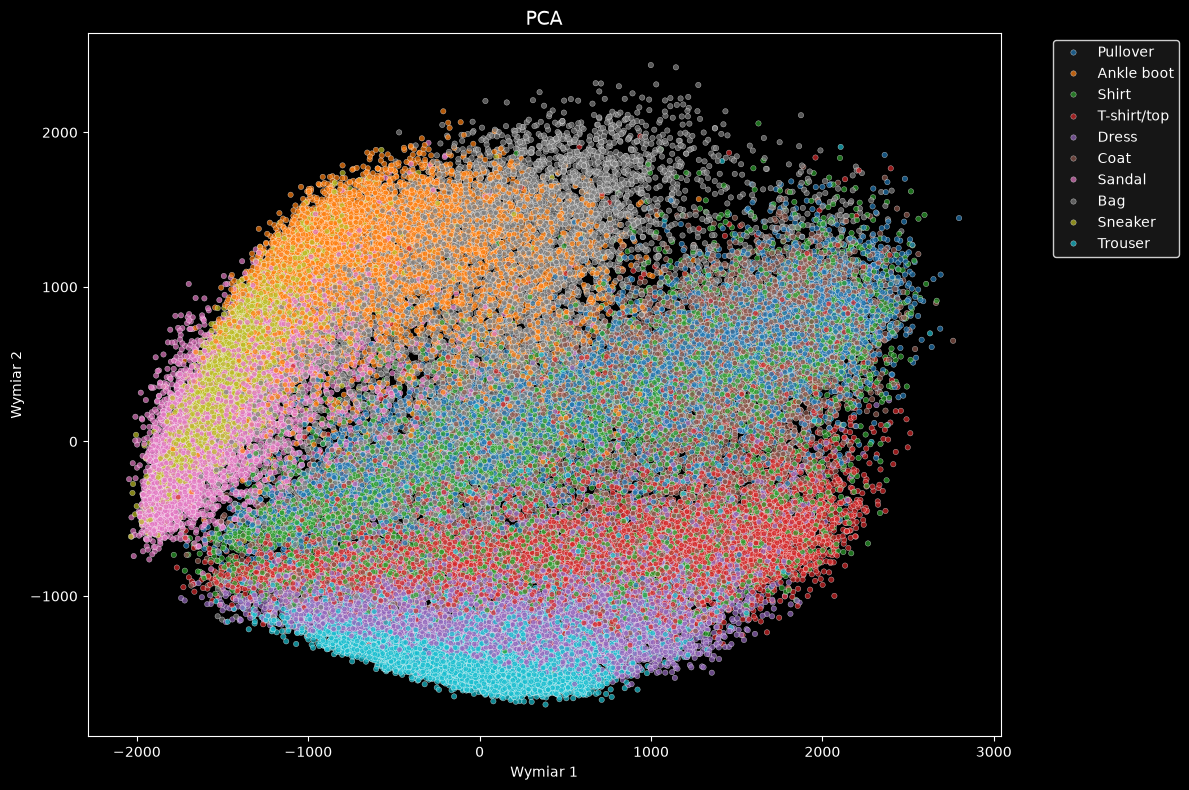

In [4]:
pca = PCA(n_components=2)
data_pca = pca.fit_transform(df_pixel_only)

generate_plot_and_save(data_pca, mapped_labels, 'PCA')


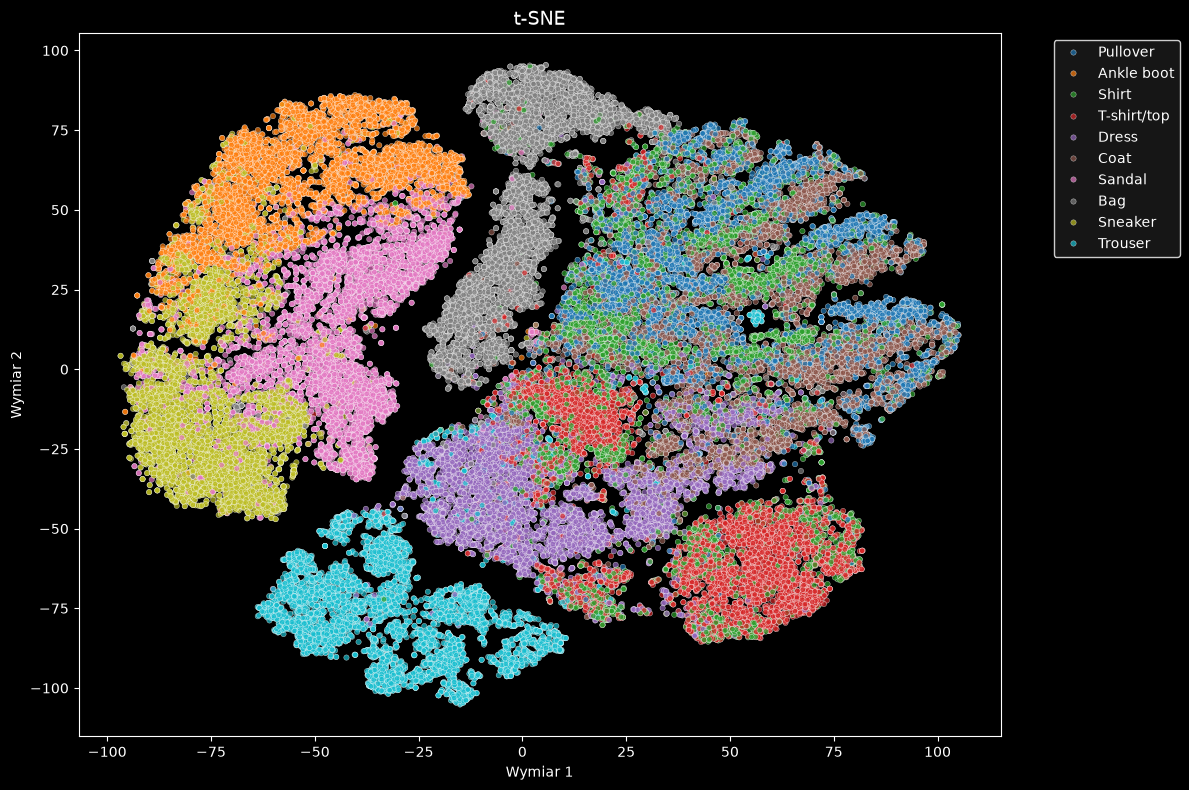

In [5]:
tsne = TSNE(n_components=2, perplexity=30.0, random_state=42)
tsne_data = tsne.fit_transform(df_pixel_only)

generate_plot_and_save(tsne_data, mapped_labels, 't-SNE')

C:\Users\jacek\DataMain\development\pwr\axion\axion-challenge\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


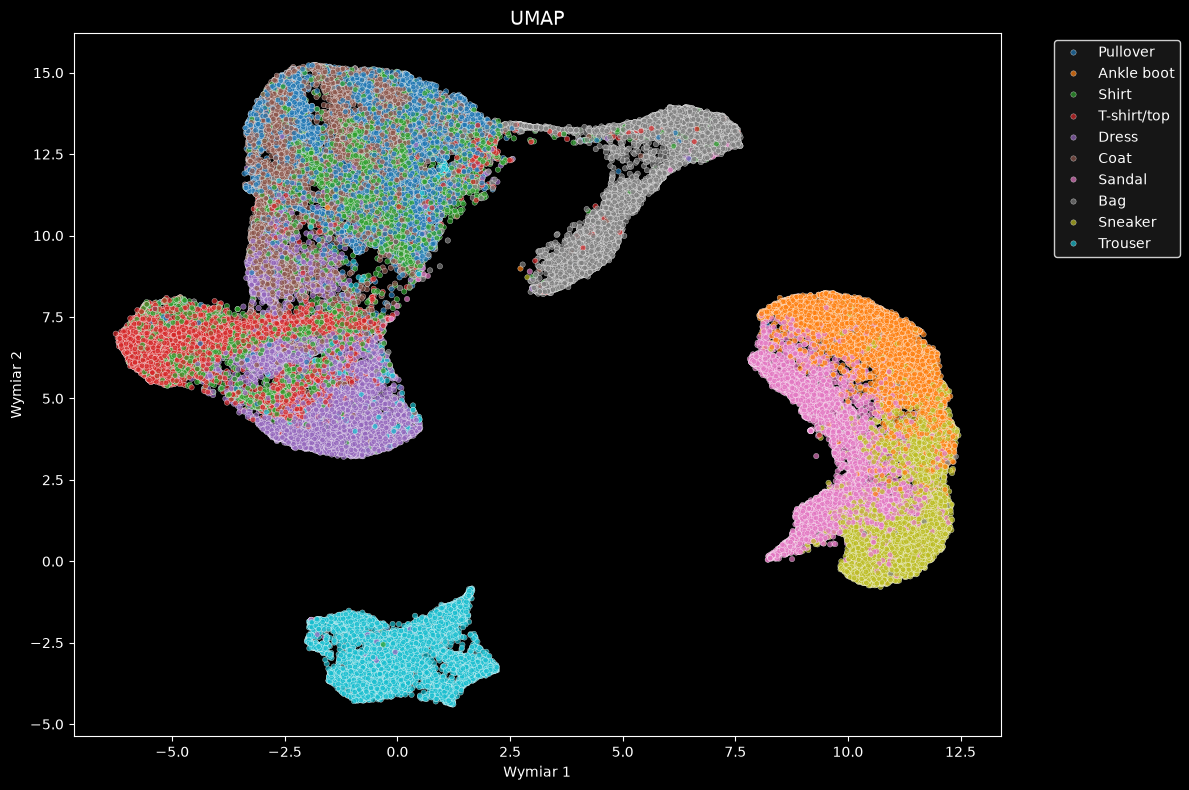

In [6]:
reducer = umap.UMAP(n_components=2, random_state=42)
umap_data = reducer.fit_transform(df_pixel_only)

generate_plot_and_save(umap_data,mapped_labels,'UMAP')


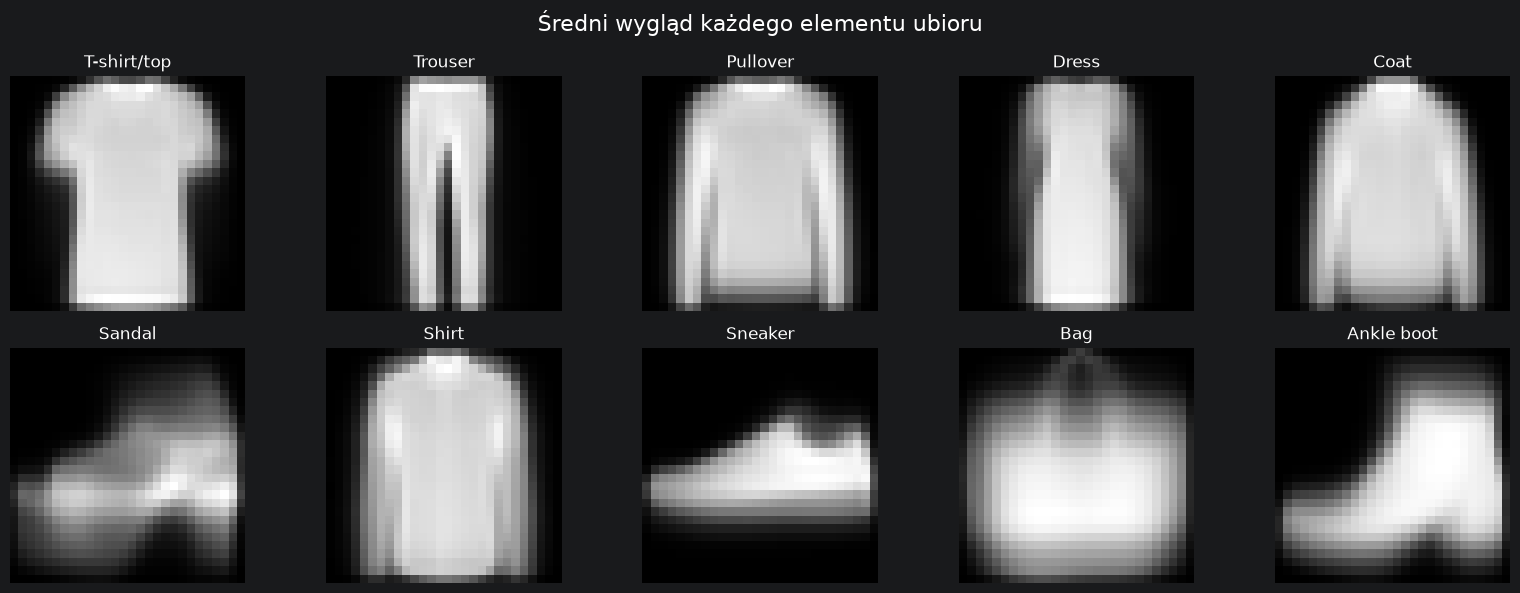

In [7]:
mean_by_class = df.groupby('label').mean()

fig, axes = plt.subplots(2, 5, figsize=(16, 6))

for label, ax in enumerate(axes.flat):
    pixels_vector = mean_by_class.loc[label].values
    pic_28x28 = pixels_vector.reshape(28, 28)


    ax.imshow(pic_28x28, cmap='gray')
    ax.set_title(clothes_dict[label])
    ax.axis('off')

plt.suptitle('Średni wygląd każdego elementu ubioru', fontsize=16)
plt.tight_layout()

images_dir = Path.cwd().parent / 'images'
images_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(images_dir / 'type-mean.png', facecolor='black', bbox_inches='tight')

plt.show()